<a href="https://colab.research.google.com/github/MassEgo88/OIBSIP/blob/main/DataScience-Task1-IrisClassification/Iris_Flower_Classification_Using_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#PART 1: PROJECT OVERVIEW
Project: Iris Flower Classification Using Machine Learning

Track: Data Science

Objective: Predict iris flower species using their physical measurements.

The three species are:

Setosa

Versicolor

Virginica

The four numerical features are:

Sepal Length

Sepal Width

Petal Length

Petal Width

#PART 2: TECHNOLOGY STACK
Google Colab

Python

Pandas

NumPy

Matplotlib

Seaborn

Scikit-learn

Joblib

GitHub

#PART 3: COMPLETE PYTHON SOURCE CODE

In [ ]:
# CELL 1: Import libraries
# Importing the libraries required for data manipulation, visualisation, machine learning, model evaluation and model saving.


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV,
    StratifiedKFold
)

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
# CELL 2: Upload and load the existing dataset
# Upload the existing CSV dataset from the computer and load it into a Pandas DataFrame

from google.colab import files
import io

uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Dataset loaded successfully.")
print("Dataset dimensions:", df.shape)

display(df.head())

Saving iris_dataset.csv to iris_dataset (1).csv
Dataset loaded successfully.
Dataset dimensions: (150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [ ]:
# CELL 3: Inspect the dataset
# Examining the dataset structure, column names, data types, statistical summaries, missing values and duplicate records

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all"))

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:")
print(df.duplicated().sum())

Dataset shape: (150, 5)

Column names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'species']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

Statistical summary:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
count,150.000000,150.000000,150.000000,150.000000,150
unique,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,setosa
freq,NaN,NaN,NaN,NaN,50
mean,5.843333,3.057333,3.758000,1.199333,NaN
std,0.828066,0.435866,1.765298,0.762238,NaN
min,4.300000,2.000000,1.000000,0.100000,NaN
25%,5.100000,2.800000,1.600000,0.300000,NaN
50%,5.800000,3.000000,4.350000,1.300000,NaN
75%,6.400000,3.300000,5.100000,1.800000,NaN



Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Duplicate records:
1


In [ ]:
# CELL 4: Data cleaning and preparation
# Standardise column names, remove duplicate records, identify the target variable and separate independent variables from the target variable.

df.columns = df.columns.str.strip()

df = df.drop_duplicates().copy()

possible_targets = [
    "species",
    "class",
    "target",
    "variety"
]

target_column = next(
    (
        col for col in df.columns
        if col.lower() in possible_targets
    ),
    None
)

if target_column is None:
    raise ValueError(
        "Target column not found. "
        "Please specify the correct column name."
    )

df = df.dropna(subset=[target_column])

X = df.drop(columns=[target_column]).copy()
y = df[target_column].copy()

id_columns = [
    col for col in X.columns
    if col.lower() in ["id", "index", "unnamed: 0"]
]

X = X.drop(columns=id_columns)

print("Target column:", target_column)
print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget classes:")
print(y.unique())

print("\nPrepared dataset shape:", X.shape)

Target column: species

Features:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Target classes:
['setosa' 'versicolor' 'virginica']

Prepared dataset shape: (149, 4)


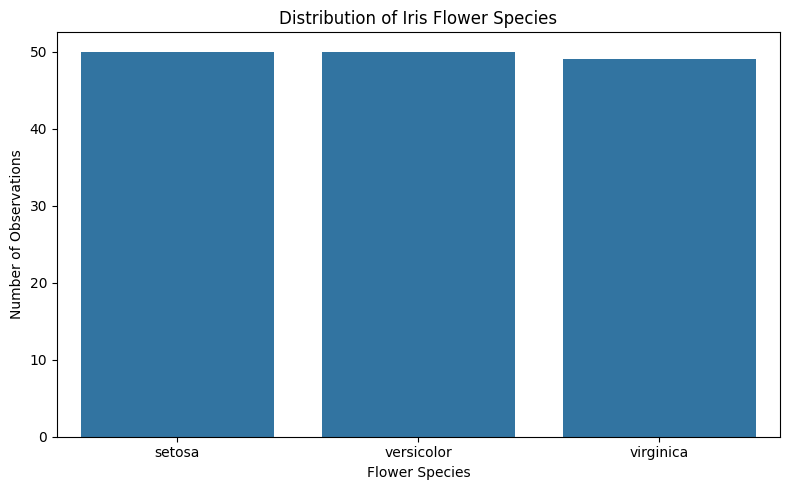

In [ ]:
# CELL 5: Exploratory Data Analysis – Species distribution
# Examine the number of observations belonging to each flower species. This helps identify possible class imbalance.

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x=target_column
)

plt.title("Distribution of Iris Flower Species")
plt.xlabel("Flower Species")
plt.ylabel("Number of Observations")

plt.tight_layout()
plt.show()

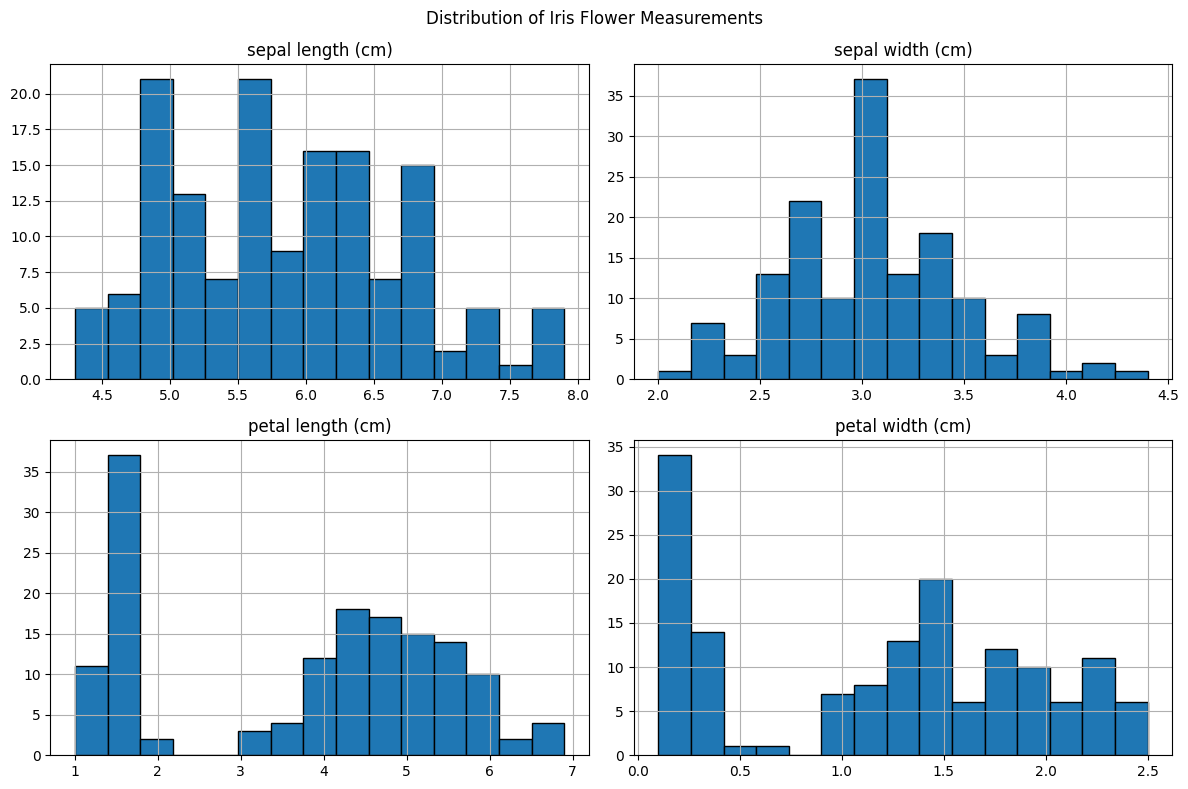

In [ ]:
# CELL 6: Feature distribution analysis
# Use histograms to examine the distribution of numerical flower measurements and identify patterns or unusual values.

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

X[numeric_features].hist(
    figsize=(12, 8),
    bins=15,
    edgecolor="black"
)

plt.suptitle("Distribution of Iris Flower Measurements")
plt.tight_layout()
plt.show()

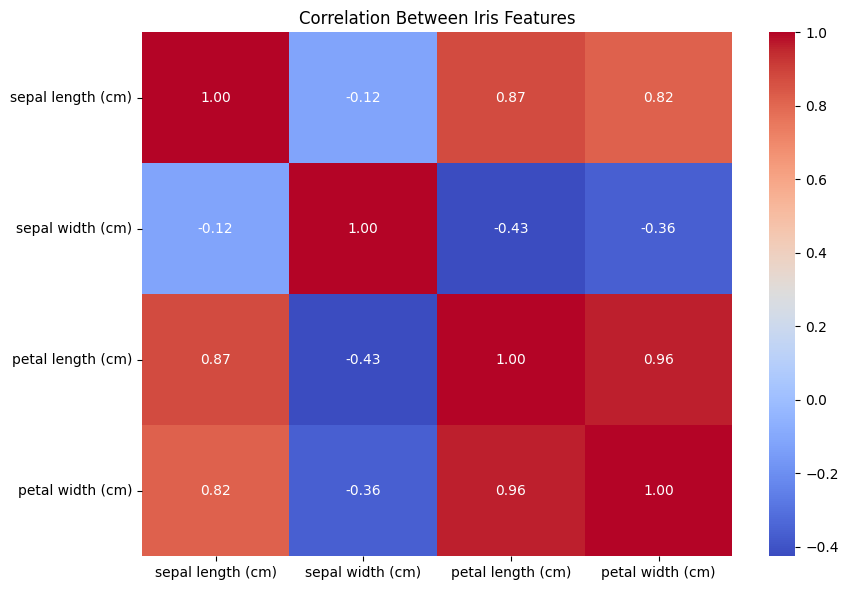

In [ ]:
# CELL 7: Correlation analysis
# Calculating correlations between numerical features to understand the strength and direction of their relationships.

correlation_matrix = X[numeric_features].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Iris Features")
plt.tight_layout()
plt.show()

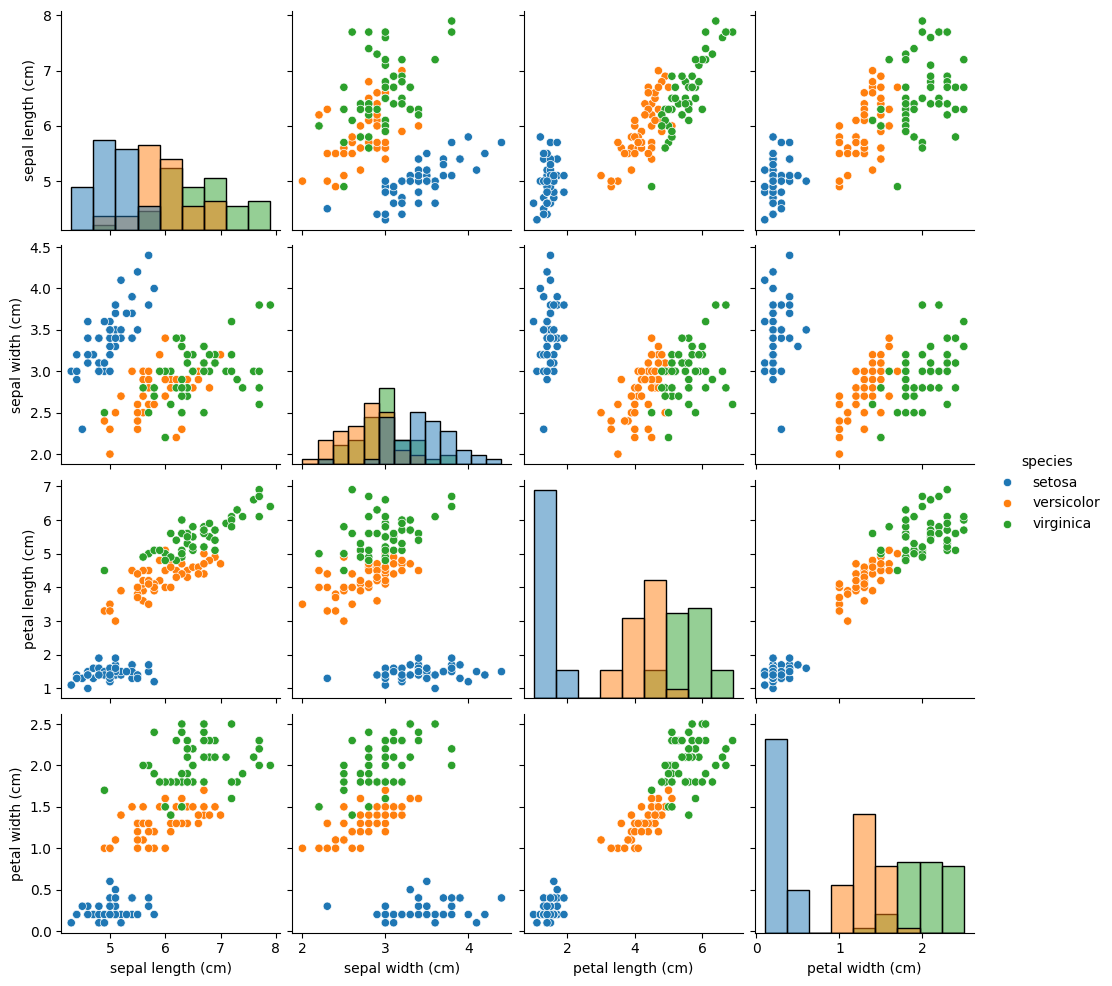

In [ ]:
# CELL 8: Feature relationship analysis
#Using pair plots to examine relationships between flower measurements and determine whether the species form distinguishable groups.

eda_data = pd.concat(
    [X, y.rename(target_column)],
    axis=1
)

sns.pairplot(
    eda_data,
    hue=target_column,
    diag_kind="hist"
)

plt.show()

In [ ]:
# CELL 9: Split training and testing data
# Dividing the dataset into 80% training data and 20% testing data. Stratification maintains the class distribution across both datasets.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

Training observations: 119
Testing observations: 30

Training class distribution:
species
setosa        40
versicolor    40
virginica     39
Name: count, dtype: int64


In [ ]:
# CELL 10: Build the preprocessing pipeline
# Handling missing values, standardise numerical variables and encode categorical variables where necessary.

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [ ]:
# CELL 11: Train multiple machine learning models
# Training five classification algorithms using the same preprocessing pipeline. Compare their performance using accuracy, precision, recall and F1-score.

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),

    "Support Vector Machine": SVC(
        probability=True,
        random_state=42
    ),

    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    )
}

results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions,
            average="weighted",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions,
            average="weighted",
            zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions,
            average="weighted",
            zero_division=0
        )
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

display(results_df)

,Model,Accuracy,Precision,Recall,F1 Score
0,Support Vector Machine,0.966667,0.969697,0.966667,0.966583
1,Logistic Regression,0.933333,0.933333,0.933333,0.933333
2,Random Forest,0.933333,0.933333,0.933333,0.933333
3,K-Nearest Neighbors,0.933333,0.944444,0.933333,0.932660
4,Decision Tree,0.933333,0.933333,0.933333,0.933333


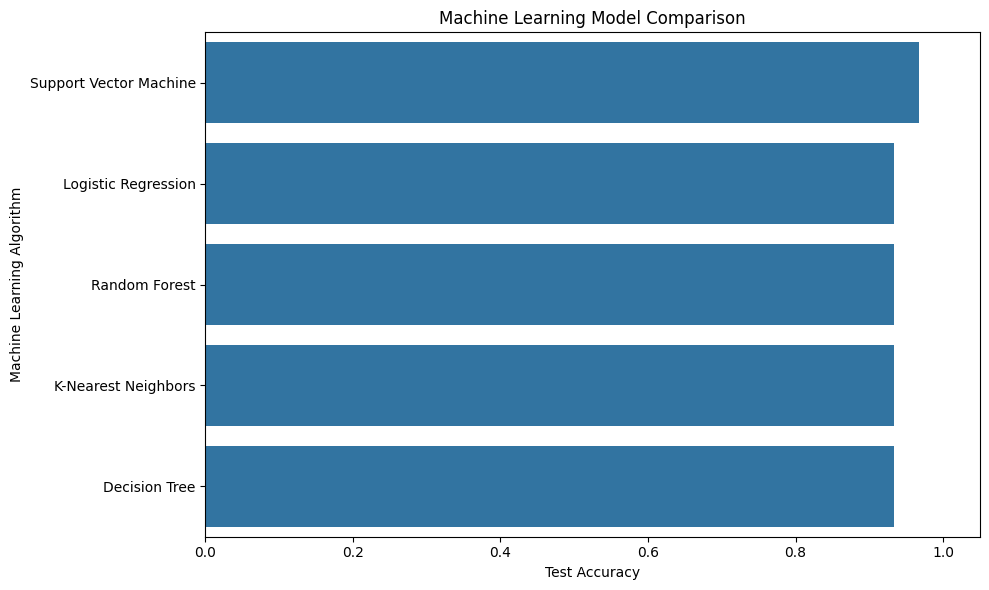

In [ ]:
# CELL 12: Visualise model performance
# Comparing the accuracy of the five classification algorithms using a bar chart.

plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Accuracy",
    y="Model"
)

plt.title("Machine Learning Model Comparison")
plt.xlabel("Test Accuracy")
plt.ylabel("Machine Learning Algorithm")

plt.xlim(0, 1.05)

plt.tight_layout()
plt.show()

In [ ]:
# CELL 13: Cross-validation
# Applying five-fold stratified cross-validation to the training dataset to evaluate model consistency. The test dataset remains separate.

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy"
    )

    cv_results.append({
        "Model": name,
        "Mean CV Accuracy": scores.mean(),
        "Standard Deviation": scores.std()
    })

cv_df = pd.DataFrame(cv_results)

cv_df = cv_df.sort_values(
    by="Mean CV Accuracy",
    ascending=False
).reset_index(drop=True)

display(cv_df)

,Model,Mean CV Accuracy,Standard Deviation
0,Logistic Regression,0.965580,0.050647
1,Support Vector Machine,0.965217,0.069565
2,K-Nearest Neighbors,0.957246,0.047636
3,Random Forest,0.931884,0.059099
4,Decision Tree,0.931884,0.059099


In [ ]:
# CELL 14: Hyperparameter tuning
# Useing GridSearchCV to identify a suitable Random Forest configuration by testing different combinations of parameters using cross-validation.

rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(random_state=42))
])

param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 5, 10],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2]
}

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation accuracy:")
print(grid_search.best_score_)

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best parameters:
{'model__max_depth': None, 'model__min_samples_leaf': 2, 'model__min_samples_split': 5, 'model__n_estimators': 100}

Best cross-validation accuracy:
0.9402173913043479


In [ ]:
# CELL 15: Final model evaluation
# Evaluating the tuned model using the previously unseen testing dataset.

final_predictions = best_model.predict(X_test)

print("Final Model Evaluation")
print("=" * 40)

print(
    "Accuracy:",
    round(accuracy_score(y_test, final_predictions), 4)
)

print(
    "Precision:",
    round(precision_score(
        y_test, final_predictions,
        average="weighted",
        zero_division=0
    ), 4)
)

print(
    "Recall:",
    round(recall_score(
        y_test, final_predictions,
        average="weighted",
        zero_division=0
    ), 4)
)

print(
    "F1 Score:",
    round(f1_score(
        y_test, final_predictions,
        average="weighted",
        zero_division=0
    ), 4)
)

print("\nClassification Report:")
print(classification_report(
    y_test,
    final_predictions,
    zero_division=0
))

Final Model Evaluation
Accuracy: 0.9667
Precision: 0.9697
Recall: 0.9667
F1 Score: 0.9666

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



,Feature,Importance
2,numeric__petal length (cm),0.437888
3,numeric__petal width (cm),0.435026
0,numeric__sepal length (cm),0.109554
1,numeric__sepal width (cm),0.017532


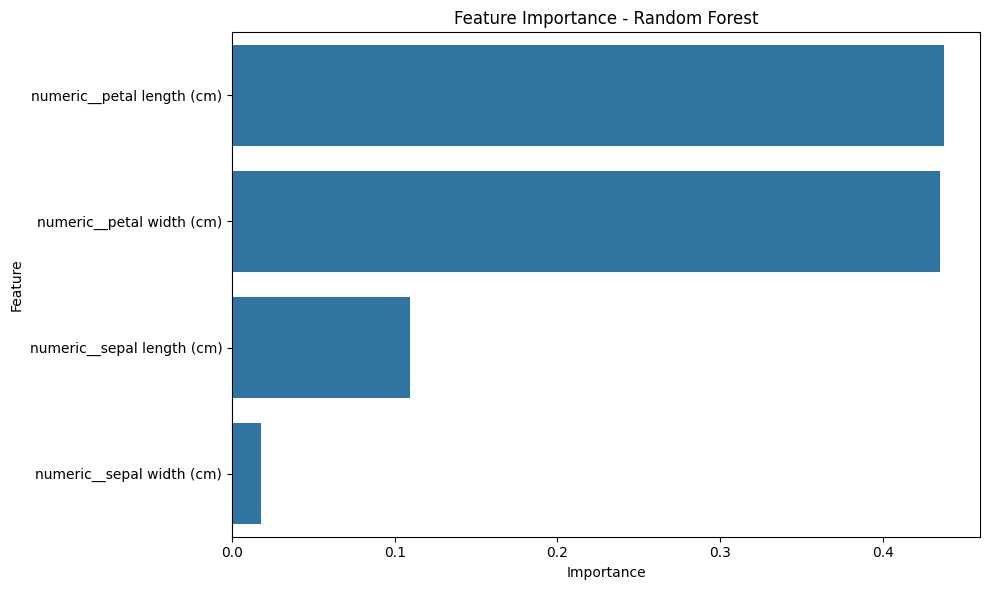

In [ ]:
# CELL 17: Feature importance
# Identifing which flower measurements contribute most to the Random Forest model's predictions.

feature_names = (
    best_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importance = (
    best_model
    .named_steps["model"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values(
    by="Importance",
    ascending=False
)

display(importance_df)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance - Random Forest")
plt.tight_layout()
plt.show()

In [ ]:
#CELL 18: Make predictions using new data
# Demonstrating how the trained model can predict the species of a new flower using its physical measurements.

# Example measurements for a standard four-feature Iris dataset

new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=X.columns
)

prediction = best_model.predict(new_flower)

print("Predicted flower species:", prediction[0])

if hasattr(best_model, "predict_proba"):

    probabilities = best_model.predict_proba(
        new_flower
    )

    probability_df = pd.DataFrame(
        probabilities,
        columns=best_model.classes_
    )

    print("\nPrediction probabilities:")
    display(probability_df)

Predicted flower species: setosa

Prediction probabilities:


,setosa,versicolor,virginica
0,1.0,0.0,0.0


In [ ]:
#CELL 19: Save the trained machine learning model
# Saving the complete trained pipeline, including preprocessing and model parameters, so that it can be reused without retraining.

import joblib

model_filename = "iris_classification_model.pkl"

joblib.dump(
    best_model,
    model_filename
)

print("Model saved successfully.")

Model saved successfully.


In [ ]:
# CELL 20: Download the trained model
# Downloading the saved model from Google Colab to the local computer.

from google.colab import files

files.download(
    "iris_classification_model.pkl"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# CELL 21: Export project results
# Exporting the model comparison, cross-validation results, feature importance and final predictions into CSV files for reporting and portfolio documentation.

results_df.to_csv(
    "model_comparison.csv",
    index=False
)

cv_df.to_csv(
    "cross_validation_results.csv",
    index=False
)

importance_df.to_csv(
    "feature_importance.csv",
    index=False
)

prediction_results = pd.DataFrame({
    "Actual Species": y_test.values,
    "Predicted Species": final_predictions
})

prediction_results.to_csv(
    "prediction_results.csv",
    index=False
)

print("All project reports exported successfully.")

All project reports exported successfully.


In [ ]:
# CELL 22: Generate final project summary
# Presenting the final project statistics and model performance in a concise summary.

final_accuracy = accuracy_score(
    y_test,
    final_predictions
)

print("=" * 55)
print("IRIS FLOWER CLASSIFICATION - PROJECT SUMMARY")
print("=" * 55)

print("Dataset observations:", len(df))
print("Number of features:", X.shape[1])
print("Number of species:", y.nunique())

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nBest tuned model: Random Forest")

print(
    "Best CV accuracy:",
    round(grid_search.best_score_, 4)
)

print(
    "Final test accuracy:",
    round(final_accuracy, 4)
)

print("\nSpecies identified:")
print(list(y.unique()))

print("\nProject completed successfully.")

IRIS FLOWER CLASSIFICATION - PROJECT SUMMARY
Dataset observations: 149
Number of features: 4
Number of species: 3
Training observations: 119
Testing observations: 30

Best tuned model: Random Forest
Best CV accuracy: 0.9402
Final test accuracy: 0.9667

Species identified:
['setosa', 'versicolor', 'virginica']

Project completed successfully.


#PART 4: FINAL PROJECT DELIVERABLES
The completed project will contain:

Fully documented Google Colab notebook.

Existing Iris dataset.

Data cleaning and exploratory analysis.

Visualisation outputs.

Five trained machine learning algorithms.

Model comparison report.

Cross-validation report.

Hyperparameter tuning results.

Final model evaluation.

Confusion matrix.

Feature importance analysis.

Prediction results.

Saved machine learning model.

GitHub README documentation.

##Recommended GitHub folder structure
Iris-Flower-Classification/
│
├── Iris_Flower_Classification.ipynb
├── dataset/
│   └── iris.csv
│
├── models/
│   └── iris_classification_model.pkl
│
├── results/
│   ├── model_comparison.csv
│   ├── cross_validation_results.csv
│   ├── feature_importance.csv
│   └── prediction_results.csv
│
└── README.md

#PART 5: QUALITY AND TECHNICAL CONSIDERATIONS
The following principles will be maintained throughout the project:

The existing dataset will be used rather than downloading a replacement.

Training and testing data will remain separate.

Cross-validation will only use the training dataset.

Preprocessing will be performed within machine learning pipelines to prevent data leakage.

Model performance will be evaluated using multiple metrics.

The final model will be evaluated on unseen data.

Results will be interpreted rather than simply reported.

**Important:** The prediction example assumes the standard four Iris measurement columns. If the existing dataset has different column names or additional features, the prediction input must be adjusted accordingly. Also, the final Random Forest model should be compared against the other algorithms before concluding that it is the best-performing model.

#PART 6: PROJECT CONCLUSION
The purpose of this project is to demonstrate practical knowledge of the complete Data Science lifecycle, including data preparation, exploratory analysis, machine learning, model optimisation, evaluation and deployment preparation.